In [ ]:

%pip install -q datasets pandas numpy matplotlib seaborn


In [ ]:

from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb")

print(dataset)


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [ ]:
# Step 3. Inspect the structure
print("Dataset splits:", dataset.keys())

print("\nTraining rows:", len(dataset["train"]))
print("Test rows:", len(dataset["test"]))

print("\nFeatures:")
print(dataset["train"].features)

print("\nFirst training record:")
print(dataset["train"][0])


Dataset splits: dict_keys(['train', 'test', 'unsupervised'])

Training rows: 25000
Test rows: 25000

Features:
{'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}

First training record:
{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her

In [ ]:
# Step 4. Convert to Pandas for EDA


import pandas as pd

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())
display(train_df.sample(5, random_state=42))


Training shape: (25000, 2)
Test shape: (25000, 2)


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


,text,label
6868,"Dumb is as dumb does, in this thoroughly unint...",0
24016,I dug out from my garage some old musicals and...,1
9668,After watching this movie I was honestly disap...,0
13640,This movie was nominated for best picture but ...,1
14018,Just like Al Gore shook us up with his painful...,1


In [ ]:
# Step 5. Check data quality


print("Training data types:")
print(train_df.dtypes)

print("\nMissing values:")
print(train_df.isna().sum())

print("\nExact duplicate rows:")
print(train_df.duplicated().sum())

print("\nLabel counts:")
print(train_df["label"].value_counts().sort_index())

print("\nUnique labels:")
print(sorted(train_df["label"].unique()))


Training data types:
text     object
label     int64
dtype: object

Missing values:
text     0
label    0
dtype: int64

Exact duplicate rows:
96

Label counts:
label
0    12500
1    12500
Name: count, dtype: int64

Unique labels:
[np.int64(0), np.int64(1)]


In [ ]:

# Calculate text length features for EDA
train_df["character_count"] = train_df["text"].str.len()

train_df["word_count"] = train_df["text"].str.split().str.len()

# Summary statistics
display(
    train_df[["character_count", "word_count"]].describe()
)


,character_count,word_count
count,25000.00000,25000.000000
mean,1325.06964,233.787200
std,1003.13367,173.733032
min,52.00000,10.000000
25%,702.00000,127.000000
50%,979.00000,174.000000
75%,1614.00000,284.000000
max,13704.00000,2470.000000


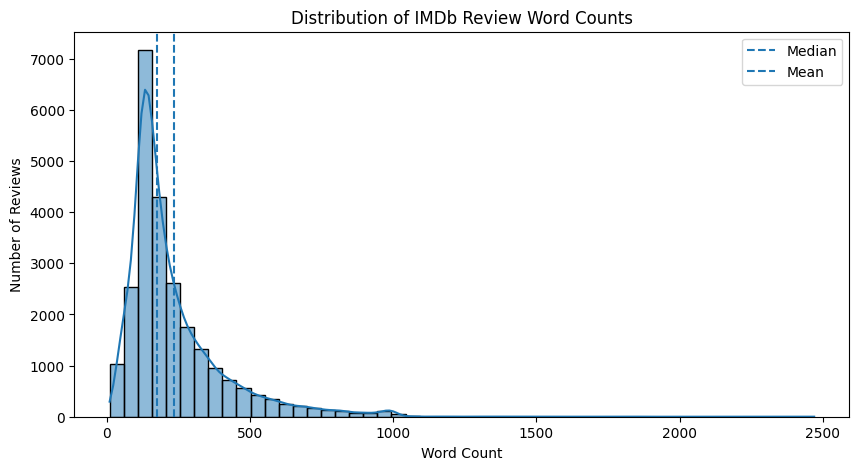

In [ ]:
# Step 7 — Visualize the word-count distribution


import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x="word_count",
    bins=50,
    kde=True
)

plt.axvline(
    train_df["word_count"].median(),
    linestyle="--",
    label="Median"
)

plt.axvline(
    train_df["word_count"].mean(),
    linestyle="--",
    label="Mean"
)

plt.title("Distribution of IMDb Review Word Counts")
plt.xlabel("Word Count")
plt.ylabel("Number of Reviews")
plt.legend()
plt.show()


In [ ]:
# Step 8 — Compare review length by sentiment


# Map numeric labels to readable names
train_df["sentiment"] = train_df["label"].map({
    0: "Negative",
    1: "Positive"
})

# Compare review length distributions
display(
    train_df.groupby("sentiment")["word_count"]
    .describe()
    .round(2)
)


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
Negative,12500.0,230.87,166.66,10.0,128.0,174.0,278.0,1522.0
Positive,12500.0,236.71,180.49,12.0,125.0,174.0,291.0,2470.0


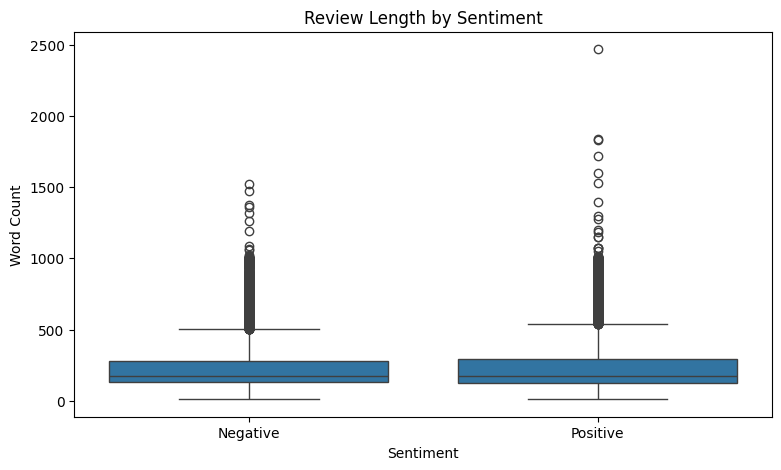

In [ ]:
# Step 9 — Visualize length by sentiment


import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=train_df,
    x="sentiment",
    y="word_count"
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Word Count")
plt.show()


In [ ]:
# Step 10 — Inspect the actual text quality


# Inspect HTML-related patterns in the raw reviews

html_break_count = train_df["text"].str.contains(
    r"<br\s*/?>",
    case=False,
    regex=True
).sum()

html_tag_count = train_df["text"].str.contains(
    r"<[^>]+>",
    regex=True
).sum()

print("Reviews containing HTML line breaks:", html_break_count)
print("Reviews containing HTML-like tags:", html_tag_count)

# Display examples containing HTML breaks
html_examples = train_df.loc[
    train_df["text"].str.contains(
        r"<br\s*/?>",
        case=False,
        regex=True
    ),
    "text"
].head(3)

for i, review in enumerate(html_examples, start=1):
    print(f"\nExample {i}:")
    print(review[:500])


Reviews containing HTML line breaks: 14665
Reviews containing HTML-like tags: 14667

Example 1:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent

Example 2:
If only to avoid making this type of film in the future. This film is interesting as an experiment but tells no cogent story.<br /><br />One might feel virtuous for sitting thru it because it touches on so many IMPORTANT issues but it does so without any discernable motive. The viewer comes away with no new perspectives (unless one comes up with one while one's mind wanders, as it will in

In [ ]:
# Step 11 — Inspect duplicate reviews


# Investigate exact duplicate review text
duplicate_text_mask = train_df["text"].duplicated(keep=False)

duplicate_reviews = train_df.loc[
    duplicate_text_mask,
    ["text", "label"]
].sort_values("text")

print("Rows involved in repeated review text:",
      len(duplicate_reviews))

print("Unique repeated review texts:",
      duplicate_reviews["text"].nunique())

print("\nLabel counts among repeated review rows:")
print(duplicate_reviews["label"].value_counts().sort_index())

# Check whether any repeated text has conflicting labels
labels_per_text = duplicate_reviews.groupby("text")["label"].nunique()

print("\nRepeated texts with conflicting labels:",
      (labels_per_text > 1).sum())

display(duplicate_reviews.head(6))


Rows involved in repeated review text: 188
Unique repeated review texts: 92

Label counts among repeated review rows:
label
0    132
1     56
Name: count, dtype: int64

Repeated texts with conflicting labels: 0


,text,label
934,'Dead Letter Office' is a low-budget film abou...,0
4217,'Dead Letter Office' is a low-budget film abou...,0
18590,".......Playing Kaddiddlehopper, Col San Fernan...",1
21740,".......Playing Kaddiddlehopper, Col San Fernan...",1
7176,"<br /><br />Back in his youth, the old man had...",0
7177,"<br /><br />Back in his youth, the old man had...",0


In [ ]:
# Step 12 — Check train–test overlap


train_texts = set(train_df["text"])
test_texts = set(test_df["text"])

overlap_texts = train_texts.intersection(test_texts)

print("Unique training review texts:", len(train_texts))
print("Unique test review texts:", len(test_texts))
print("Exact review texts appearing in both splits:", len(overlap_texts))

if overlap_texts:
    print("\nExamples of overlapping reviews:")
    for review in list(overlap_texts)[:3]:
        print("\n", review[:250])




Unique training review texts: 24904
Unique test review texts: 24801
Exact review texts appearing in both splits: 123

Examples of overlapping reviews:

 An updated version of a theme which has been done before. While that in and of itself is not bad, this movie doesn't reach the ring like the other "inherent and pure" evil ones do. <br /><br />Predictable, ambitious attempt that falls short of the ma

 Contains spoilers. <br /><br />The British director J. Lee Thompson made some excellent films, notably 'Ice Cold in Alex' and 'Cape Fear', but 'Country Dance' is one of his more curious offerings. The story is set among the upper classes of rural Sco

 I used to always love the bill because of its great script and characters, but lately i feel as though it has turned into an emotional type of soap. If you look at promotional pictures/posters of the bill now you will see either two of the officers h


In [ ]:
# Step 13 — Check whether overlapping reviews have matching labels


# Find exact text overlap and compare labels
overlap_df = train_df[
    train_df["text"].isin(overlap_texts)
][["text", "label"]].merge(
    test_df[["text", "label"]],
    on="text",
    how="inner",
    suffixes=("_train", "_test")
)

print("Matching review-label pairs:", len(overlap_df))

print("\nLabel agreement:")
print(
    (overlap_df["label_train"] == overlap_df["label_test"])
    .value_counts()
    .rename(index={True: "Same label", False: "Different label"})
)

print("\nOverlapping reviews with conflicting labels:")
display(
    overlap_df[
        overlap_df["label_train"] != overlap_df["label_test"]
    ].head()
)


Matching review-label pairs: 123

Label agreement:
Same label    123
Name: count, dtype: int64

Overlapping reviews with conflicting labels:


,text,label_train,label_test


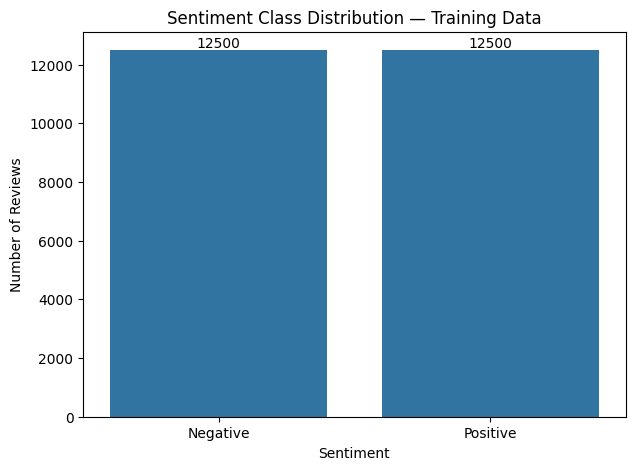

In [ ]:
# Step 14 — Investigate class balance visually


import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=train_df,
    x="sentiment"
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Sentiment Class Distribution — Training Data")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()


In [ ]:
# Step 15 — Analyze the most frequent words


from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re
import pandas as pd

def get_word_counts(texts):
    counts = Counter()

    for text in texts:
        words = re.findall(r"\b[a-zA-Z]+\b", text.lower())
        words = [
            word for word in words
            if word not in ENGLISH_STOP_WORDS
        ]
        counts.update(words)

    return counts

negative_counts = get_word_counts(
    train_df.loc[train_df["label"] == 0, "text"]
)

positive_counts = get_word_counts(
    train_df.loc[train_df["label"] == 1, "text"]
)

print("Top 20 words in negative reviews:")
display(pd.DataFrame(
    negative_counts.most_common(20),
    columns=["word", "frequency"]
))

print("Top 20 words in positive reviews:")
display(pd.DataFrame(
    positive_counts.most_common(20),
    columns=["word", "frequency"]
))


Top 20 words in negative reviews:


,word,frequency
0,br,52636
1,s,30770
2,movie,24969
3,t,20584
4,film,19219
5,like,11241
6,just,10620
7,good,7423
8,bad,7401
9,really,6263


Top 20 words in positive reviews:


,word,frequency
0,br,49235
1,s,32832
2,film,20940
3,movie,19078
4,t,13803
5,like,9040
6,good,7724
7,just,7154
8,story,6779
9,time,6516


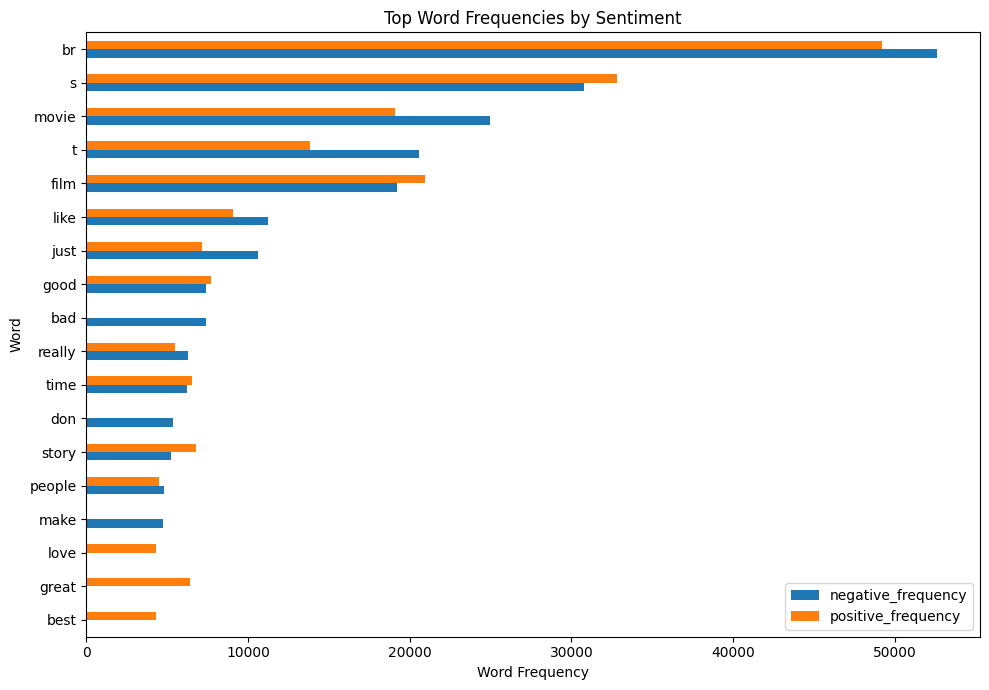

In [ ]:
# Step 16 — Compare the most frequent words visually


import matplotlib.pyplot as plt
import pandas as pd

top_n = 15

negative_top = pd.DataFrame(
    negative_counts.most_common(top_n),
    columns=["word", "negative_frequency"]
)

positive_top = pd.DataFrame(
    positive_counts.most_common(top_n),
    columns=["word", "positive_frequency"]
)

comparison = pd.merge(
    negative_top,
    positive_top,
    on="word",
    how="outer"
).fillna(0)

comparison = comparison.sort_values(
    "negative_frequency",
    ascending=True
)

comparison.plot(
    x="word",
    y=["negative_frequency", "positive_frequency"],
    kind="barh",
    figsize=(10, 7)
)

plt.title("Top Word Frequencies by Sentiment")
plt.xlabel("Word Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()


In [ ]:
# Step 17 — Check review length and sentiment together


# Group reviews by length
train_df["length_group"] = pd.cut(
    train_df["word_count"],
    bins=[0, 100, 250, 500, float("inf")],
    labels=["Short (1–100)", "Medium (101–250)",
            "Long (251–500)", "Very long (500+)"]
)

length_sentiment = (
    train_df.groupby("length_group", observed=False)["label"]
    .agg(["count", "mean"])
    .reset_index()
)

length_sentiment["positive_percentage"] = (
    length_sentiment["mean"] * 100
)

length_sentiment = length_sentiment.drop(columns="mean")

display(length_sentiment.round(2))


,length_group,count,positive_percentage
0,Short (1–100),2982,54.93
1,Medium (101–250),14461,48.43
2,Long (251–500),5539,49.68
3,Very long (500+),2018,54.86


In [ ]:
# Step 18 — Inspect punctuation and special characters before deciding how to preprocess the text.


import re

sample_text = train_df["text"].iloc[0]

print("Original review:")
print(sample_text[:1000])

print("\nHTML tags found:")
print(re.findall(r"<[^>]+>", sample_text)[:20])

print("\nPunctuation characters:")
print(sorted(set(re.findall(r"[^\w\s]", sample_text))) )


Original review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and

In [ ]:
# Step 19 — Inspect text quality across the entire dataset


import re

text_series = train_df["text"]

html_reviews = text_series.str.contains(
    r"<[^>]+>", regex=True
).sum()

url_reviews = text_series.str.contains(
    r"https?://|www\.",
    case=False,
    regex=True
).sum()

control_char_reviews = text_series.str.contains(
    r"[\x00-\x08\x0B\x0C\x0E-\x1F]",
    regex=True
).sum()

print("Reviews containing HTML tags:", html_reviews)
print("Reviews containing URLs:", url_reviews)
print("Reviews containing control characters:", control_char_reviews)


Reviews containing HTML tags: 14667
Reviews containing URLs: 97
Reviews containing control characters: 2


In [ ]:
# Step 20 — Inspect unusually short reviews


shortest_reviews = (
    train_df.nsmallest(10, "word_count")
    [["text", "word_count", "sentiment"]]
)

display(shortest_reviews.to_string(index=False))


'                                                                                                         text  word_count sentiment\n                                                        I wouldn\'t rent this one even on dollar rental night.          10  Negative\n                                                         This movie is terrible but it has some good effects.          10  Negative\n                                            You\'d better choose Paul Verhoeven\'s even if you have watched it.          11  Negative\n                                             Ming The Merciless does a little Bardwork and a movie most foul!          12  Negative\n                                       Adrian Pasdar is excellent is this film. He makes a fascinating woman.          12  Positive\n                             Long, boring, blasphemous. Never have I been so glad to see ending credits roll.          14  Negative\nComment this movie is impossible. Is terrible, very improbable, b

In [ ]:
# Step 21 — Inspect the longest reviews


longest_reviews = (
    train_df.nlargest(5, "word_count")
    [["word_count", "sentiment", "text"]]
)

for _, row in longest_reviews.iterrows():
    print("=" * 80)
    print("Word count:", row["word_count"])
    print("Sentiment:", row["sentiment"])
    print("Review preview:")
    print(row["text"][:700])
    print()


Word count: 2470
Sentiment: Positive
Review preview:
Match 1: Tag Team Table Match Bubba Ray and Spike Dudley vs Eddie Guerrero and Chris Benoit Bubba Ray and Spike Dudley started things off with a Tag Team Table Match against Eddie Guerrero and Chris Benoit. According to the rules of the match, both opponents have to go through tables in order to get the win. Benoit and Guerrero heated up early on by taking turns hammering first Spike and then Bubba Ray. A German suplex by Benoit to Bubba took the wind out of the Dudley brother. Spike tried to help his brother, but the referee restrained him while Benoit and Guerrero ganged up on him in the corner. With Benoit stomping away on Bubba, Guerrero set up a table outside. Spike dashed into the ring

Word count: 1839
Sentiment: Positive
Review preview:
Titanic directed by James Cameron presents a fictional love story on the historical setting of the Titanic. The plot is simple, noncomplicated, or not for those who love plots that twist and t

In [ ]:
# Step 22 — Check for empty or whitespace-only reviews


# Check empty and whitespace-only reviews
empty_reviews = train_df["text"].str.len().eq(0).sum()

whitespace_only_reviews = (
    train_df["text"].str.strip().eq("")
).sum()

print("Empty reviews:", empty_reviews)
print("Whitespace-only reviews:", whitespace_only_reviews)


Empty reviews: 0
Whitespace-only reviews: 0


In [ ]:
# Step 23 — Check for unusually high repetition within reviews


# Count repeated occurrences of a word within each review
train_df["word_count"] = train_df["text"].str.split().str.len()

train_df["unique_word_count"] = (
    train_df["text"]
    .str.lower()
    .str.findall(r"\b[a-z]+\b")
    .apply(lambda words: len(set(words)))
)

train_df["unique_word_ratio"] = (
    train_df["unique_word_count"] / train_df["word_count"]
)

display(
    train_df[
        ["word_count", "unique_word_count", "unique_word_ratio"]
    ].describe().round(3)
)


,word_count,unique_word_count,unique_word_ratio
count,25000.000,25000.000,25000.000
mean,233.787,140.439,0.655
std,173.733,80.439,0.098
min,10.000,10.000,0.037
25%,127.000,88.000,0.590
50%,174.000,115.000,0.655
75%,284.000,171.000,0.716
max,2470.000,674.000,1.211


In [ ]:
# Step 24 — Inspect the review with the lowest unique-word ratio


lowest_ratio_review = train_df.loc[
    train_df["unique_word_ratio"].idxmin()
]

print("Word count:", lowest_ratio_review["word_count"])
print("Unique word count:", lowest_ratio_review["unique_word_count"])
print("Unique word ratio:", lowest_ratio_review["unique_word_ratio"])
print("Sentiment:", lowest_ratio_review["sentiment"])

print("\nReview text:")
print(lowest_ratio_review["text"][:1500])


Word count: 296
Unique word count: 11
Unique word ratio: 0.037162162162162164
Sentiment: Positive

Review text:
Smallville episode Justice is the best episode of Smallville ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! It's my favorite episode of Smallville! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! !


In [ ]:

# Count exclamation marks in each review
train_df["exclamation_count"] = train_df["text"].str.count("!")

print("Reviews containing exclamation marks:",
      (train_df["exclamation_count"] > 0).sum())

print("Reviews with more than 10 exclamation marks:",
      (train_df["exclamation_count"] > 10).sum())

print("Reviews with more than 50 exclamation marks:",
      (train_df["exclamation_count"] > 50).sum())

print("\nExclamation-count summary:")
print(train_df["exclamation_count"].describe())


Reviews containing exclamation marks: 8595
Reviews with more than 10 exclamation marks: 248
Reviews with more than 50 exclamation marks: 10

Exclamation-count summary:
count    25000.000000
mean         0.982400
std          3.711172
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max        282.000000
Name: exclamation_count, dtype: float64


In [ ]:
# Step 26 — Check whether punctuation usage differs by sentiment


punctuation_by_sentiment = (
    train_df.groupby("sentiment")["exclamation_count"]
    .agg(["mean", "median", "sum"])
    .round(3)
)

display(punctuation_by_sentiment)


,mean,median,sum
sentiment,,,
Negative,1.019,0.0,12741
Positive,0.946,0.0,11819


In [ ]:
# Step 27 — Check the distribution of sentence counts


import re

def count_sentences(text):
    # Simple exploratory estimate, not a perfect NLP sentence splitter
    sentences = re.split(r'[.!?]+', text)
    return sum(1 for sentence in sentences if sentence.strip())

train_df["sentence_count"] = train_df["text"].apply(count_sentences)

display(
    train_df["sentence_count"]
    .describe()
    .round(2)
    .to_frame()
)


,sentence_count
count,25000.00
mean,13.38
std,9.37
min,1.00
25%,7.00
50%,11.00
75%,16.00
max,150.00


In [ ]:
# Step 28 - Let's compare sentence counts by sentiment


display(
    train_df.groupby("sentiment")["sentence_count"]
    .describe()
    .round(2)
)


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
Negative,12500.0,13.72,9.52,1.0,8.0,11.0,17.0,145.0
Positive,12500.0,13.04,9.21,1.0,7.0,10.0,16.0,150.0


In [ ]:
# Step 29 — Compare train and test data quality


# Add comparable exploratory features to the test set
test_df["word_count"] = test_df["text"].str.split().str.len()

test_df["sentiment"] = test_df["label"].map({
    0: "Negative",
    1: "Positive"
})

split_summary = pd.DataFrame({
    "train": [
        len(train_df),
        train_df["word_count"].mean(),
        train_df["text"].str.contains(r"<[^>]+>", regex=True).mean() * 100,
        train_df["label"].mean() * 100
    ],
    "test": [
        len(test_df),
        test_df["word_count"].mean(),
        test_df["text"].str.contains(r"<[^>]+>", regex=True).mean() * 100,
        test_df["label"].mean() * 100
    ]
}, index=[
    "Rows",
    "Mean word count",
    "Reviews with HTML tags (%)",
    "Positive reviews (%)"
])

display(split_summary.round(2))


,train,test
Rows,25000.00,25000.00
Mean word count,233.79,228.53
Reviews with HTML tags (%),58.67,58.14
Positive reviews (%),50.00,50.00


In [ ]:
# Step 30 — Analyze DistilBERT token lengths


%pip install -q transformers



In [ ]:

from transformers import AutoTokenizer

model_name = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("Tokenizer loaded:", model_name)
print("Model maximum position embeddings:", tokenizer.model_max_length)


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Tokenizer loaded: distilbert/distilbert-base-uncased-finetuned-sst-2-english
Model maximum position embeddings: 512


In [ ]:
# Step 31 — Measure actual token lengths


from tqdm.auto import tqdm
import numpy as np
import pandas as pd

texts = train_df["text"].tolist()
token_lengths = []

batch_size = 256

for start in tqdm(range(0, len(texts), batch_size)):
    batch = texts[start:start + batch_size]

    encoded = tokenizer(
        batch,
        add_special_tokens=True,
        truncation=False
    )

    token_lengths.extend(
        len(input_ids)
        for input_ids in encoded["input_ids"]
    )

train_df["token_length"] = token_lengths

display(
    train_df["token_length"]
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame()
    .round(2)
)


  0%|          | 0/98 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (720 > 512). Running this sequence through the model will result in indexing errors


,token_length
count,25000.00
mean,313.87
std,234.30
min,13.00
50%,233.00
75%,382.00
90%,618.00
95%,806.05
99%,1206.00
max,3127.00


In [ ]:
# Step 32 — Calculate how much text each sequence length would retain


import pandas as pd

limits = [128, 256, 512]
total_reviews = len(token_lengths)

results = []

for limit in limits:
    truncated = sum(length > limit for length in token_lengths)

    results.append({
        "max_length": limit,
        "reviews_exceeding_limit": truncated,
        "percentage_exceeding": round(
            truncated / total_reviews * 100, 2
        )
    })

display(pd.DataFrame(results))


,max_length,reviews_exceeding_limit,percentage_exceeding
0,128,22325,89.30
1,256,11063,44.25
2,512,3701,14.80


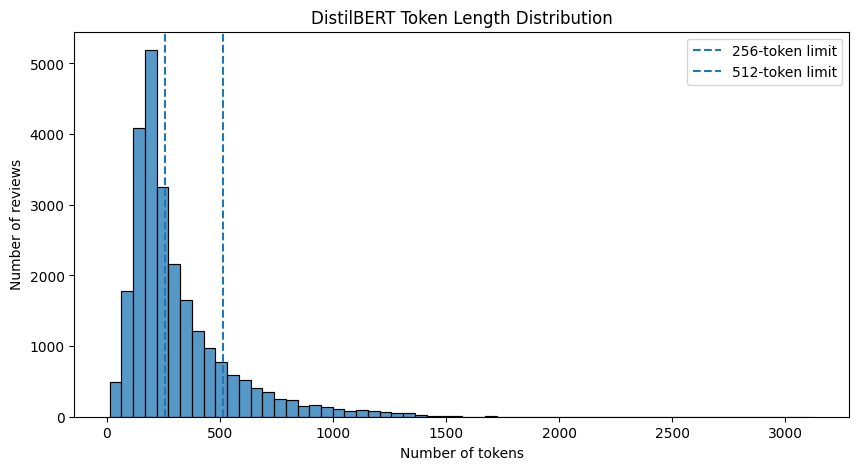

In [ ]:
# Step 33 — Finish EDA with a text-length visualization


import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["token_length"],
    bins=60,
    kde=False
)

plt.axvline(256, linestyle="--", label="256-token limit")
plt.axvline(512, linestyle="--", label="512-token limit")

plt.title("DistilBERT Token Length Distribution")
plt.xlabel("Number of tokens")
plt.ylabel("Number of reviews")
plt.legend()
plt.show()


In [ ]:
# Step 35 — Final EDA checkpoint

# Inspect common HTML-like patterns before cleaning
import re
from collections import Counter

html_pattern_counts = Counter()

for text in train_df["text"].head(1000):
    patterns = re.findall(r"<[^>]+>", text)
    html_pattern_counts.update(patterns)

html_pattern_counts.most_common(15)

[('<br />', 4558)]

In [ ]:
# Step 35A: Inspect remaining HTML patterns

import re
from collections import Counter

html_patterns = Counter()
html_entities = Counter()

for review in train_df["text"].dropna():
    # Find HTML-like tags
    html_patterns.update(
        re.findall(r"<[^>]+>", review)
    )

    # Find HTML entities, such as &amp; or &quot;
    html_entities.update(
        re.findall(r"&(?:[a-zA-Z]+|#\d+|#x[0-9a-fA-F]+);", review)
    )

print("Top HTML tags:")
print(html_patterns.most_common(20))

print("\nTop HTML entities:")
print(html_entities.most_common(20))



Top HTML tags:
[('<br />', 101862), ('<i>', 7), ('</i>', 7), ('<=8.<br />', 2), ('<hr>', 1), ('< who was to be a victim, but woman-power trumps evil scientist every time.<br />', 1), ('<http://rogerebert.suntimes.com/apps/pbcs.dll/section?category=ANSWERMAN>', 1), ('< and make notes for my partial "review" to show how foolish the movie is. "Resident Evil" (horror) or "Dude, Where\'s My Car?" (comedy) I can watch over and over again and still enjoy! But this...!<br />', 1), ("< $600 per screen its opening weekend, and just over $400 each, after its month's theater run in latter 2002. Overall gross was $261K, which I'd doubt could cover cast and crew's hotel and food for a week on location.<br />", 1), ('<grin>', 1), ('< than 30 minutes of watching, being bored and irritated. <br />', 1), ('<SPOILER>', 1), ('</SPOILER>', 1), ('<em>', 1), ('</em>', 1), ('<3 <br />', 1), ('<<<sigh>', 1), ('<sp?) classic "Romeo & Juliet". Guess I\'ll have to rent that next.<br />', 1)]

Top HTML entities:
[

In [ ]:
# Final EDA — Step 35B: Check train/test overlap

# Find exact review texts shared by train and test
train_texts = set(train_df["text"])
test_texts = set(test_df["text"])

overlap_texts = train_texts.intersection(test_texts)

print("Unique training reviews:", len(train_texts))
print("Unique test reviews:", len(test_texts))
print("Exact texts shared:", len(overlap_texts))

# Check whether overlapping reviews have matching labels
train_labels = (
    train_df.drop_duplicates("text")
    .set_index("text")["label"]
)

test_labels = (
    test_df.drop_duplicates("text")
    .set_index("text")["label"]
)

label_conflicts = [
    text for text in overlap_texts
    if train_labels[text] != test_labels[text]
]

print("Overlapping texts with conflicting labels:", len(label_conflicts))

Unique training reviews: 24904
Unique test reviews: 24801
Exact texts shared: 123
Overlapping texts with conflicting labels: 0
